In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

sns.set_theme()
sns.set_style("white")

# Is it worth using
# We need to analyse it and decide if merging it is an option
clientes = pd.read_csv("data/clientes.csv", index_col="customer_id",
                       float_precision="round_trip")

df = pd.read_csv("data/train.csv", index_col="ID",
                       float_precision="round_trip")

test = pd.read_csv("data/test.csv", index_col="ID",
                       float_precision="round_trip")

# df_merged = df.merge(
#    clientes,
#    on="customer_id",
#    how="left",
#    validate="many_to_one"
#)
#
#print("Merged rows:", len(df_merged))

# Project Goals
### Escrever aqui objetivo inicial do projeto etc (Contins e Corigo)

In [2]:
print("Train database dimensions:")
df.shape

Train database dimensions:


(6534, 38)

In [3]:
print("Test database dimensions:")
test.shape

Test database dimensions:


(986, 37)

In [4]:
print("Target variable value counts:")
print(df["repeat_purchase_90d"].value_counts())

print("\nTarget variable percentages:")
print((df["repeat_purchase_90d"].value_counts(normalize=True) * 100).round(2))

Target variable value counts:
repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64

Target variable percentages:
repeat_purchase_90d
1    55.92
0    44.08
Name: proportion, dtype: float64


We can see that the database has a decent size (6534 rows) and the target value is decently well distributed.
Our goal is to predict if clients are going to repeat a purchase with the highest hit rate possible.

We have 2 id's the first (ID) iterates all the train database, the second (customer_id) is our foreign key that connects the clients database.

In [5]:
pd.set_option('display.max_columns', None)
df.head(2)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150,112.656252,349.49,508.81,47.0,NaN,0.0,0.0,1.0,349.49,2.0,858.3,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566,1683.795178,84.38,4222.15,93.0,117.657696,0.0,0.0,0.0,0.00,0.0,0.0,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510


In [6]:
test.head(2)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000006,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409266,22,1,40.0,3905,122,46287.23,379.403525,528.297548,2.72,3198.00,31.942149,48.035282,0,0.0,6,1295.82,9,2498.90,23,9140.12,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,0.621602
10000008,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,63.0,3613,58,243340.48,4195.525517,2545.945318,569.52,11031.74,62.280702,46.416113,0,0.0,1,3137.11,2,5086.36,4,16252.35,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,-1.318874


In [7]:
clientes.head(2)

,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
customer_id,,,,,,,,,,,,
842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021


In [8]:
df.columns.difference(test.columns)

Index(['repeat_purchase_90d'], dtype='str')

### Problem: Target variable is different in both datasets

### Aqui deve ser feito um resumo incial das variáveis, explicar qual é a target variable, os ID's, etc. Falar também dos clientes.csv

## Missing Values (Part 1)

In [9]:
pd.DataFrame({
    "Number of nulls in train": df.isnull().sum(),
    "% of nulls in train": round(df.isnull().mean() * 100, 1),
    "Number of nulls in test": test.isnull().sum(),
    "% of nulls in test": round(test.isnull().mean() * 100, 1)}
)

,Number of nulls in train,% of nulls in train,Number of nulls in test,% of nulls in test
Custo,65,1.0,0.0,0.0
N_ Detalhes,65,1.0,0.0,0.0
Total Bruto,65,1.0,0.0,0.0
Total Desc_ Global,65,1.0,0.0,0.0
Total Desc_ Linha,65,1.0,0.0,0.0
Total Imp_,65,1.0,0.0,0.0
Total Liquido,65,1.0,0.0,0.0
Total Portes,65,1.0,0.0,0.0
Total a Pagar,65,1.0,0.0,0.0
commercial_zone,65,1.0,0.0,0.0


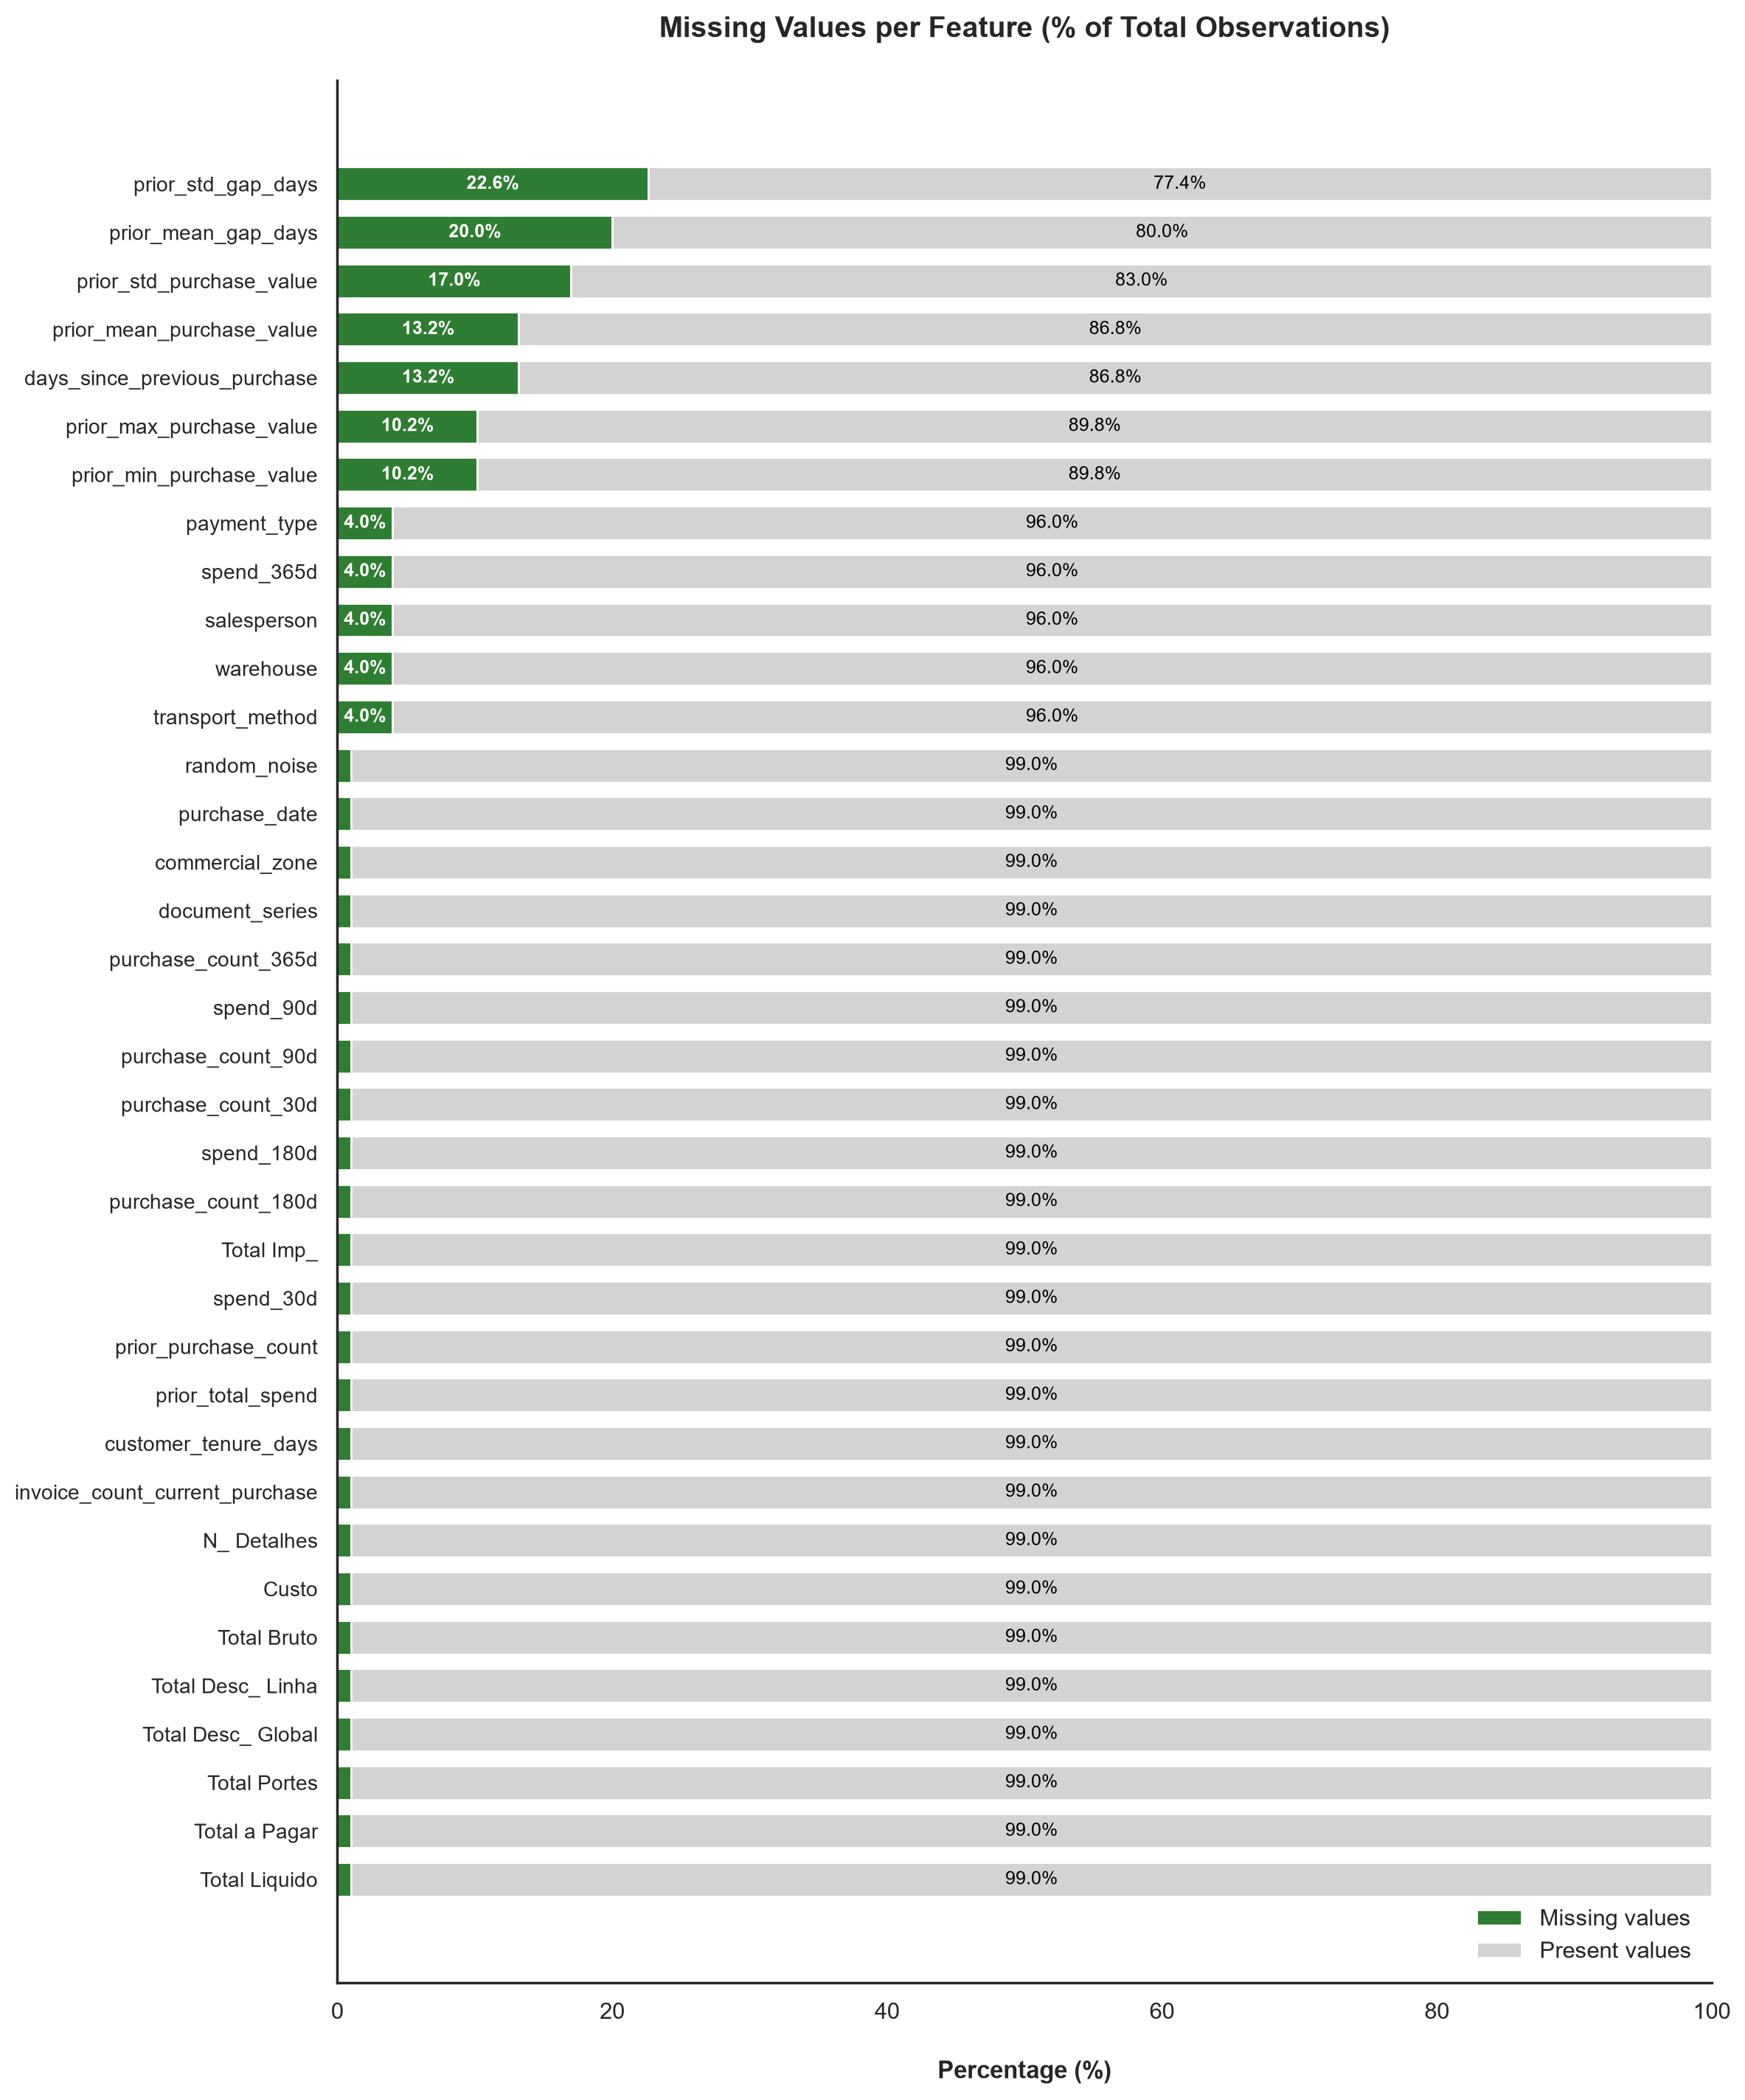

In [10]:
# Missing and percentages

missing_pct = (df.isnull().mean() * 100).round(1).sort_values(ascending=True)
missing_pct = missing_pct[missing_pct > 0]

present_pct = (100 - missing_pct).round(1)
column_names = missing_pct.index.tolist()

fig_height = max(6, len(column_names) * 0.4)
fig, ax = plt.subplots(figsize=(12, fig_height))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

p1 = ax.barh(y=column_names, width=missing_pct, height=0.7, color="#2E7D32", label="Missing values")
p2 = ax.barh(y=column_names, width=present_pct, height=0.7, color="lightgrey", left=missing_pct, label="Present values")

# Percentage labels
missing_labels = [f"{val:.1f}%" if val > 2 else "" for val in missing_pct]
present_labels = [f"{val:.1f}%" if val > 2 else "" for val in present_pct]

ax.bar_label(p1, labels=missing_labels, color="white", label_type="center", fontsize=9, fontweight="bold")
ax.bar_label(p2, labels=present_labels, color="black", label_type="center", fontsize=9)

# Styling and formatting
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="none")
ax.set_title("Missing Values per Feature (% of Total Observations)\n", fontsize=14, fontweight="bold")
ax.set_xlabel("\nPercentage (%)", fontsize=12, fontweight="bold")
ax.set_xlim(0, 100)
plt.yticks(fontsize=10)
sns.despine(right=True, top=True)
plt.tight_layout()
plt.show()

In [11]:
# Identifying all columns with 65 nulls to understand if they are all in the same records (so we inderstand if we can drop them)

null_counts = df.isnull().sum()

cols_65 = null_counts[null_counts == 65].index.tolist()

print("Number of columns:", len(cols_65))
print(cols_65)

Number of columns: 24
['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'commercial_zone', 'document_series', 'purchase_date', 'random_noise']


In [12]:
df[cols_65].isnull().sum(axis=1).value_counts().sort_index()

0     6469
24      65
Name: count, dtype: int64

In [13]:
df[cols_65].isnull().all(axis=1).sum()

np.int64(65)

### Notes: (explicar melhor!!!)
We decided to delete all 65 records that have no real values and don´t make sense to keep because there isn´t info in them.

In [14]:
df = df.loc[~df[cols_65].isnull().all(axis=1)].copy()

In [15]:
pd.DataFrame({
    "Number of nulls in train": df.isnull().sum(),
    "% of nulls in train": round(df.isnull().mean() * 100, 1),
    "Number of nulls in test": test.isnull().sum(),
    "% of nulls in test": round(test.isnull().mean() * 100, 1)}
)

,Number of nulls in train,% of nulls in train,Number of nulls in test,% of nulls in test
Custo,0,0.0,0.0,0.0
N_ Detalhes,0,0.0,0.0,0.0
Total Bruto,0,0.0,0.0,0.0
Total Desc_ Global,0,0.0,0.0,0.0
Total Desc_ Linha,0,0.0,0.0,0.0
Total Imp_,0,0.0,0.0,0.0
Total Liquido,0,0.0,0.0,0.0
Total Portes,0,0.0,0.0,0.0
Total a Pagar,0,0.0,0.0,0.0
commercial_zone,0,0.0,0.0,0.0


## Duplicates

In [16]:
df.index.duplicated().sum()

np.int64(0)

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
test.index.duplicated().sum()

np.int64(0)

### Notes:
We didn´t find duplicate values so there's no need to treat duplicates in this dataset.

## Data types

In [19]:
pd.DataFrame({"df": df.dtypes, "test": test.dtypes})

,df,test
Custo,float64,float64
N_ Detalhes,float64,int64
Total Bruto,float64,float64
Total Desc_ Global,float64,float64
Total Desc_ Linha,float64,float64
Total Imp_,float64,float64
Total Liquido,float64,float64
Total Portes,float64,float64
Total a Pagar,float64,float64
commercial_zone,str,str


### Notes!!!:
Some differences between the datasets, we should correct them.
N_Detalhes, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, purchase_count_30d, purchase_count_90d, purchase_count_180d, purchase_count_365d should be an Int64
Should we convert to datetime??
Is str ok or should it be bool?

In [20]:
# CONVERT BOTH TRAIN AND TEST DATASETS

# Convert columns to datetime format
#train_data["Accident Date"] = pd.to_datetime(train_data["Accident Date"])

# Convert columns to Int64 format
#train_data["Age at Injury"] = train_data["Age at Injury"].astype("Int64")

## Info about numerical variables

In [35]:
# All in the same line
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Numerical Variables
num_df = df.select_dtypes(include="number")

stats = num_df.describe().T

# + metrics
stats["median"] = num_df.median()
stats["skew"] = num_df.skew()
stats["%_zeros"] = (num_df == 0).mean() * 100

cols_order = ["count", "mean", "std", "min", "25%", "median", "75%", "max", "skew", "%_zeros"]
stats = stats[cols_order].round(2)

print(stats)

                                 count        mean          std        min        25%     median        75%           max   skew  %_zeros
Total a Pagar                   6469.0      925.56      1335.00       0.93     188.92     476.74    1087.67  2.229721e+04   4.21     0.00
Total Bruto                     6469.0      886.15      1327.64       0.83     175.74     445.74    1036.70  2.157828e+04   4.31     0.00
Total Liquido                   6469.0      773.34      1136.36       0.76     154.38     389.91     903.37  1.812781e+04   4.15     0.00
Total Imp_                      6469.0      152.22       225.26       0.00      29.93      79.74     184.84  4.169400e+03   4.84     3.29
Total Portes                    6469.0        1.15         5.84       0.00       0.00       0.00       0.00  1.810600e+02  19.55    83.72
Total Desc_ Global              6469.0        0.35         5.12       0.00       0.00       0.00       0.00  2.184900e+02  27.46    98.30
Total Desc_ Linha               64

### Notes!!!:
Many variables with negative values should be treated! (days_since_previous_purchase, prior_mean_purchase_value,  prior_mean_gap_days, spend_365d)
Explorar os valores impossíveis e tipo de variáveis errados no EDA
A percentagem de 0's do 365d está c problemas

## Info about Categorical Variables
### Fazer aqui análise inicial das variáveis categóricas (diferentes opções por variável) para perceber anomalias e possíveis coisas a melhorar (perceber tmb o encoding no EDA)

In [22]:
# Check if there are variables with '' (empty string) values
#train_data.columns[train_data.eq('').any()].tolist() # [] -> No empty string values

In [23]:
# CONVERT BOTH TRAIN AND TEST DATASETS

# Convert columns to category format
# train_data['Claim Injury Type'] = train_data['Claim Injury Type'].astype('category')

## Separating the dataset variables in types

In [24]:
target = "repeat_purchase_90d"

# 1. Define explicit known IDs and identify high-cardinality text columns
known_ids = ["customer_id"]

# This helps separate the variables that are most likely to overfit our DB
high_cardinality = [
    c for c in df.columns 
    if c not in known_ids + [target] 
    and not pd.api.types.is_numeric_dtype(df[c]) 
    and df[c].nunique() > 0.5 * len(df)
]

identifiers = known_ids + high_cardinality

# 2. Separate numeric and categorical features (excluding identifiers and target)
numeric = [
    c for c in df.columns 
    if c not in identifiers + [target] 
    and pd.api.types.is_numeric_dtype(df[c])
]

categorical = [
    c for c in df.columns 
    if c not in identifiers + [target] + numeric
]

# 3. Numeric columns with low cardinality (categorical codes stored as numbers)
low_cardinality = {c: df[c].nunique() for c in numeric if df[c].nunique() <= 10}

# 4. Count level cardinalities for categorical variables
levels = df[categorical].nunique().sort_values(ascending=False)

# Print unique values for categorical columns with <= 4 levels
print("Unique values for categoricals with <= 4 levels:")
for column in levels[levels <= 4].index:
    vals = sorted(df[column].dropna().unique().tolist())
    print(f"{column:30s} {vals}")

# 5. Summary of variable roles
roles = {
    "identifiers": f"{len(identifiers)} {identifiers}",
    "numeric": f"{len(numeric)}, of which low-cardinality: {low_cardinality}",
    "categorical": f"{len(categorical)}, holding {int(levels.sum())} levels -> ~{int(levels.sum())} columns once encoded",
    "target": target,
}

print("\nVariable Roles Summary:")
for role, desc in roles.items():
    print(f"{role:<45} : {desc}")

Unique values for categoricals with <= 4 levels:
document_series                ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']
warehouse                      ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']

Variable Roles Summary:
identifiers                                   : 1 ['customer_id']
numeric                                       : 29, of which low-cardinality: {'invoice_count_current_purchase': 5}
categorical                                   : 7, holding 1600 levels -> ~1600 columns once encoded
target                                        : repeat_purchase_90d


We shouldn't use the id's so that the models don´t memorize specific costumer identification with no relation between them (random number).

## Target variable check

In [26]:
# Target class balance analysis
balance = df[target].value_counts(dropna=False).sort_index()

print("\nTarget Class Balance:")
print(
    balance.to_frame("rows")
    .assign(share=lambda f: (f["rows"] / len(df)).round(4))
    .to_string()
)

# Baseline score for a naive majority-class classifier
majority_acc = balance.max() / balance.sum()
print(
    f"\nAlways predicting the majority class scores "
    f"{majority_acc:.4f} accuracy and 0 recall on the minority class."
)


Target Class Balance:
                     rows   share
repeat_purchase_90d              
0                    2848  0.4403
1                    3621  0.5597

Always predicting the majority class scores 0.5597 accuracy and 0 recall on the minority class.


### Notes:
The target variable is well distributed, there are 56% of 1's and 44% of 0's

# Missing Values (after eliminating all 65 rows with 100% null values)

In [33]:
# Missing values summary
rows_with_null = df.isna().any(axis=1)
per_column = df.isna().sum()

missing_summary = pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(df):,} ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {df.shape[1]}",
    "null cells": f"{df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max():,} nulls)" if per_column.max() > 0 else "None",
}).to_frame("missing values summary")

print(missing_summary)

                               missing values summary
rows with a null              2,540 of 6,469 (39.26%)
columns with a null                          12 of 38
null cells                                      7,478
worst column         prior_std_gap_days (1,413 nulls)


### Notes!!!:
Analisar em especial estas variáveis para perceber o tipo de Missing values!!
Para o resto dos Missing Values, só depois de fazer o EDA destas variáveis e fazer flags (Flags dos impossíveis + missing values e perceber MNAR MAR E MCAR)

## Impossible Values